# A/B Testing: Facebook Ads vs AdWords (2019)

## Business Problem
As a marketing agency, we ran two ad campaigns for a client during 2019: one on **Facebook** and one on **Google AdWords**.
The client now wants to know which platform deserves more of the advertising budget.

## Research Question
> **Which ad platform is more effective in terms of clicks, conversions and overall cost-effectiveness?**

## Approach
1. Load and clean the data
2. Build a **scorecard** comparing both platforms (views, clicks, conversions, spend)
3. Study daily performance and the relationship between clicks and conversions
4. **Time analysis**: month-wise and weekday-wise trends
5. Budget efficiency and a simple "what-if" scenario
6. Final insights and recommendation

### Metrics used in this project
| Metric | Formula | Meaning |
|---|---|---|
| **CTR** (Click-Through Rate) | Clicks / Views | Share of people who saw the ad and clicked on it |
| **Conversion Rate** | Conversions / Clicks | Share of people who clicked and then completed the desired action (purchase, sign-up) |
| **CPC** (Cost per Click) | Spend / Clicks | Average price paid for one click |
| **CPA** (Cost per Acquisition) | Spend / Conversions | Average cost of getting one conversion |

## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Use the same colors for each platform in every chart
colors = {'Facebook': '#03989E', 'AdWords': '#A62372'}
platforms = ['Facebook', 'AdWords']

## 2. Data Loading and Cleaning

The dataset has **365 rows** (one for each day of 2019). The columns of both platforms are stored side by side in the same row.

In [2]:
df = pd.read_csv('ABmarketing_campaign.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (365, 17)


,Date,Facebook Ad Campaign,Facebook Ad Views,Facebook Ad Clicks,Facebook Ad Conversions,Cost per Facebook Ad,Facebook Click-Through Rate (Clicks / View),Facebook Conversion Rate (Conversions / Clicks),Facebook Cost per Click (Ad Cost / Clicks),AdWords Ad Campaign,AdWords Ad Views,AdWords Ad Clicks,AdWords Ad Conversions,Cost per AdWords Ad,AdWords Click-Through Rate (Clicks / View),AdWords Conversion Rate (Conversions / Click),AdWords Cost per Click (Ad Cost / Clicks)
0,1/1/2019,FB_Jan19,2116,18,8,$126,0.83%,42.73%,$7.14,AW_Jan19,4984,59,5,$194,1.18%,8.40%,$3.30
1,1/2/2019,FB_Jan19,3106,36,12,$104,1.15%,34.04%,$2.91,AW_Jan19,4022,71,6,$75,1.77%,7.80%,$1.05
2,1/3/2019,FB_Jan19,3105,26,8,$102,0.84%,31.45%,$3.89,AW_Jan19,3863,44,4,$141,1.13%,9.59%,$3.23
3,1/4/2019,FB_Jan19,1107,27,9,$71,2.45%,34.76%,$2.62,AW_Jan19,3911,49,5,$141,1.26%,11.08%,$2.86
4,1/5/2019,FB_Jan19,1317,15,7,$78,1.10%,47.59%,$5.38,AW_Jan19,4070,55,7,$133,1.36%,12.22%,$2.40


**Problem:** The columns containing `$` and `%` symbols are stored as text (strings), so we cannot do maths on them.

**Solution:** We keep only the useful columns (Views, Clicks, Conversions, Spend) and **stack both platforms into one table (`ads`)**.
This makes every later chart much simpler. We also calculate the rates (CTR, CPC, etc.) ourselves, so the `%` columns are not needed.

In [3]:
df['Date'] = pd.to_datetime(df['Date'])

def get_platform_data(name):
    # Returns the clean daily data of one platform
    return pd.DataFrame({
        'Date': df['Date'],
        'Platform': name,
        'Views': df[f'{name} Ad Views'],
        'Clicks': df[f'{name} Ad Clicks'],
        'Conversions': df[f'{name} Ad Conversions'],
        'Spend': df[f'Cost per {name} Ad'].str.replace('$', '', regex=False).astype(float),  # "$126" -> 126.0
    })

# Stack both platforms into one table
ads = pd.concat([get_platform_data('Facebook'), get_platform_data('AdWords')], ignore_index=True)

# Daily metrics
ads['CTR %'] = ads['Clicks'] / ads['Views'] * 100
ads['Conversion Rate %'] = ads['Conversions'] / ads['Clicks'] * 100
ads['CPC'] = ads['Spend'] / ads['Clicks']
ads['CPA'] = ads['Spend'] / ads['Conversions']

# Useful date parts
ads['Month'] = ads['Date'].dt.month
ads['Weekday'] = ads['Date'].dt.day_name()

ads.head()

,Date,Platform,Views,Clicks,Conversions,Spend,CTR %,Conversion Rate %,CPC,CPA,Month,Weekday
0,2019-01-01,Facebook,2116,18,8,126.0,0.850662,44.444444,7.000000,15.750000,1,Tuesday
1,2019-01-02,Facebook,3106,36,12,104.0,1.159047,33.333333,2.888889,8.666667,1,Wednesday
2,2019-01-03,Facebook,3105,26,8,102.0,0.837359,30.769231,3.923077,12.750000,1,Thursday
3,2019-01-04,Facebook,1107,27,9,71.0,2.439024,33.333333,2.629630,7.888889,1,Friday
4,2019-01-05,Facebook,1317,15,7,78.0,1.138952,46.666667,5.200000,11.142857,1,Saturday


In [4]:
# Quick data quality check
print('Missing values :', ads.isnull().sum().sum())
print('Duplicate rows :', ads.duplicated().sum())
print('Date range     :', ads['Date'].min().date(), 'to', ads['Date'].max().date())
print('Rows per platform:')
print(ads['Platform'].value_counts())

Missing values : 0
Duplicate rows : 0
Date range     : 2019-01-01 to 2019-12-31
Rows per platform:
Platform
Facebook    365
AdWords     365
Name: count, dtype: int64


The data is clean: there are no missing values and no duplicates. Now we can start the analysis.

## 3. Platform Scorecard (Overall Comparison)

Let us first look at the full-year totals of both platforms.

In [5]:
scorecard = ads.groupby('Platform')[['Views', 'Clicks', 'Conversions', 'Spend']].sum().loc[platforms]

scorecard['CTR %'] = scorecard['Clicks'] / scorecard['Views'] * 100
scorecard['Conversion Rate %'] = scorecard['Conversions'] / scorecard['Clicks'] * 100
scorecard['CPC'] = scorecard['Spend'] / scorecard['Clicks']
scorecard['CPA'] = scorecard['Spend'] / scorecard['Conversions']

scorecard.round(2).T

Platform,Facebook,AdWords
Views,795586.00,1721777.00
Clicks,16078.00,22040.00
Conversions,4286.00,2183.00
Spend,32040.00,49266.00
CTR %,2.02,1.28
Conversion Rate %,26.66,9.90
CPC,1.99,2.24
CPA,7.48,22.57


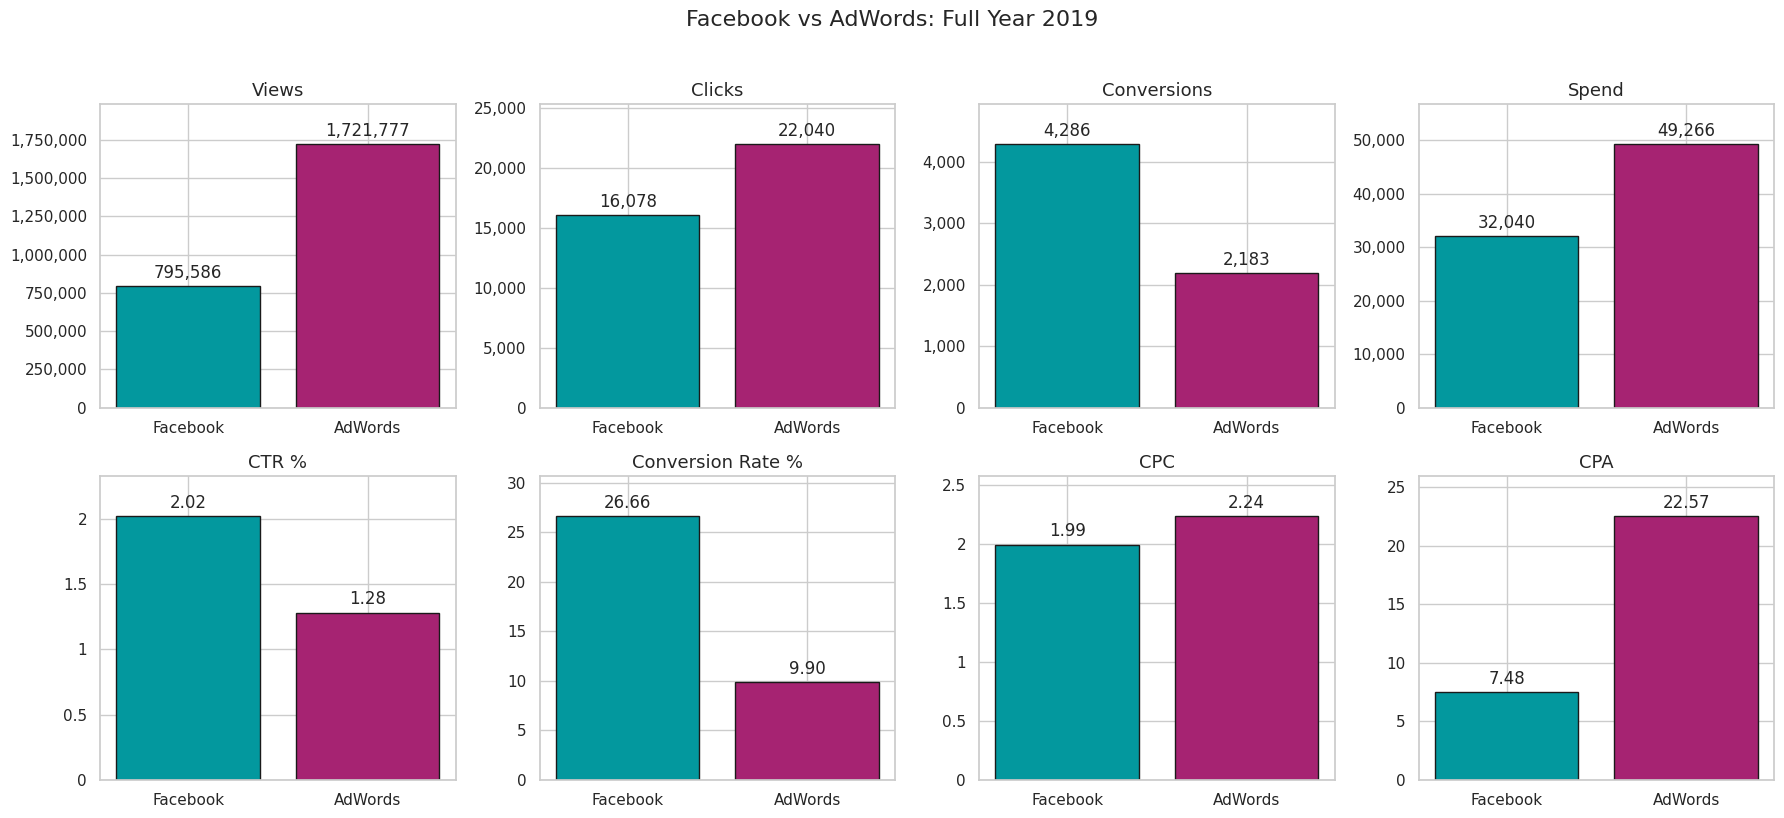

In [6]:
# Side-by-side comparison of 8 metrics
metrics = ['Views', 'Clicks', 'Conversions', 'Spend', 'CTR %', 'Conversion Rate %', 'CPC', 'CPA']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, metric in zip(axes.flat, metrics):
    values = scorecard[metric]
    bars = ax.bar(values.index, values, color=[colors[p] for p in values.index], edgecolor='k')
    # Large numbers without decimals, rates with 2 decimals
    fmt = '{:,.0f}' if metric in ['Views', 'Clicks', 'Conversions', 'Spend'] else '{:,.2f}'
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=3)
    ax.set_title(metric, fontsize=13)
    ax.set_ylim(0, values.max() * 1.15)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}' if x >= 10 else f'{x:g}'))

plt.suptitle('Facebook vs AdWords: Full Year 2019', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Observations**
- **AdWords** got more views (1.72M vs 0.80M) and more clicks (22,040 vs 16,078).
- However, **Facebook** produced **almost double the conversions** (4,286 vs 2,183) while spending **35% less**.
- Facebook also has a higher **CTR (2.02% vs 1.28%)**, which means people are more likely to click on Facebook ads.
- The biggest gap is in **Conversion Rate**: out of 100 Facebook clicks about 27 convert, but out of 100 AdWords clicks only about 10 do.
- **CPC** is similar on both platforms ($1.99 vs $2.24), so the difference is not the price of a click but the **quality of the click**.
- **CPA**: one conversion costs about $7.5 on Facebook and about $22.6 on AdWords, which makes AdWords **3 times more expensive** per conversion.

### Ad funnel: what happens for every 10,000 views?

The two platforms have very different view counts, so a fair comparison needs a common base. Here we compare them per 10,000 views.

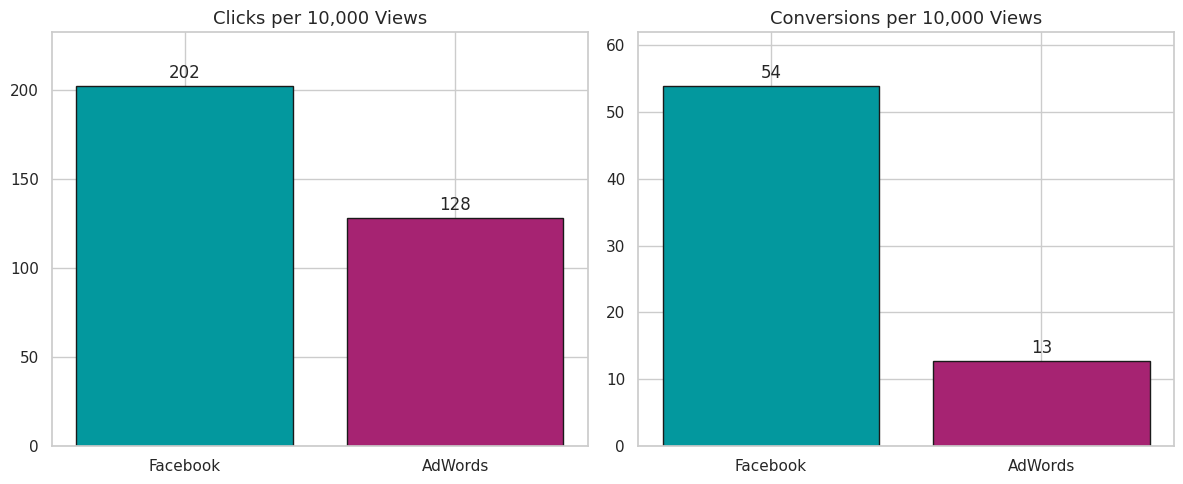

In [7]:
per_10k = pd.DataFrame({
    'Clicks': scorecard['Clicks'] / scorecard['Views'] * 10000,
    'Conversions': scorecard['Conversions'] / scorecard['Views'] * 10000,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, per_10k.columns):
    bars = ax.bar(per_10k.index, per_10k[col], color=[colors[p] for p in per_10k.index], edgecolor='k')
    ax.bar_label(bars, labels=[f'{v:,.0f}' for v in per_10k[col]], padding=3)
    ax.set_title(f'{col} per 10,000 Views', fontsize=13)
    ax.set_ylim(0, per_10k[col].max() * 1.15)
plt.tight_layout()
plt.show()

For every 10,000 views, Facebook brings about **54 conversions** while AdWords brings only about **13**. A single Facebook view is far more valuable than an AdWords view.

## 4. Daily Performance

Totals do not tell the whole story. Next we look at how each platform performed **day by day** and how consistent it was.

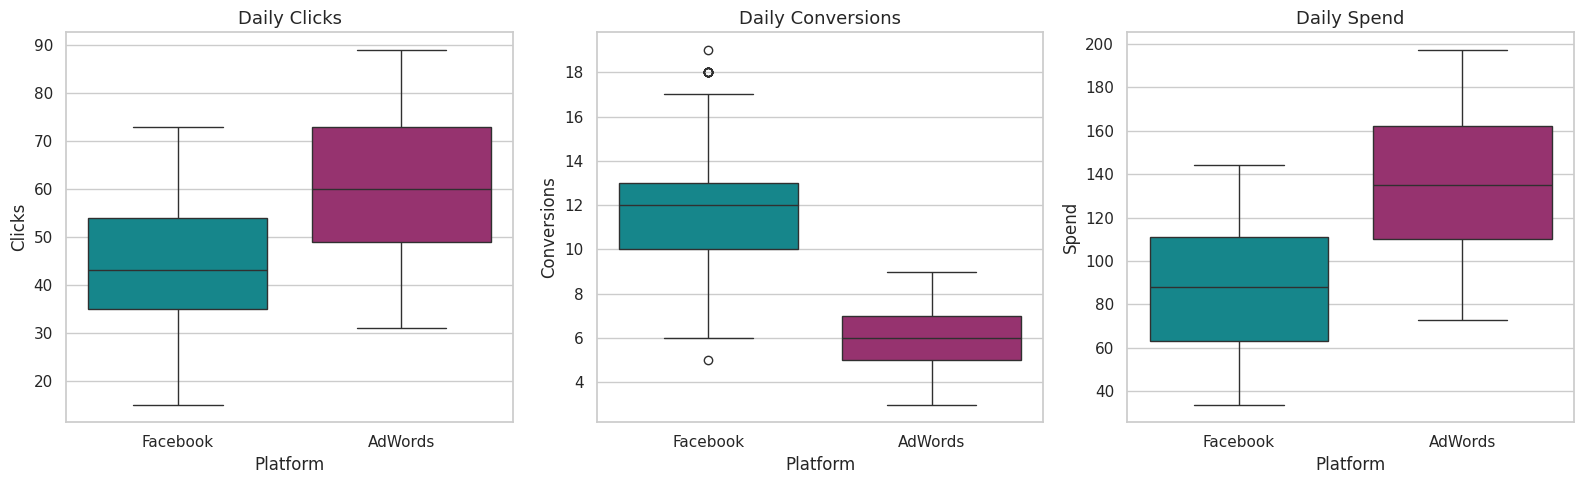

In [8]:
# Boxplot: daily spread of each metric (box = middle 50% of days, line = median)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ['Clicks', 'Conversions', 'Spend']):
    sns.boxplot(data=ads, x='Platform', y=metric, hue='Platform', order=platforms, palette=colors, legend=False, ax=ax)
    ax.set_title(f'Daily {metric}', fontsize=13)
plt.tight_layout()
plt.show()

- **Clicks:** AdWords gets more clicks per day.
- **Conversions:** The Facebook box sits far above the AdWords box and the two do not overlap, so Facebook is ahead on almost every kind of day.
- **Spend:** AdWords spends more per day than Facebook.

### How many conversions does a typical day bring? (Daily conversion groups)

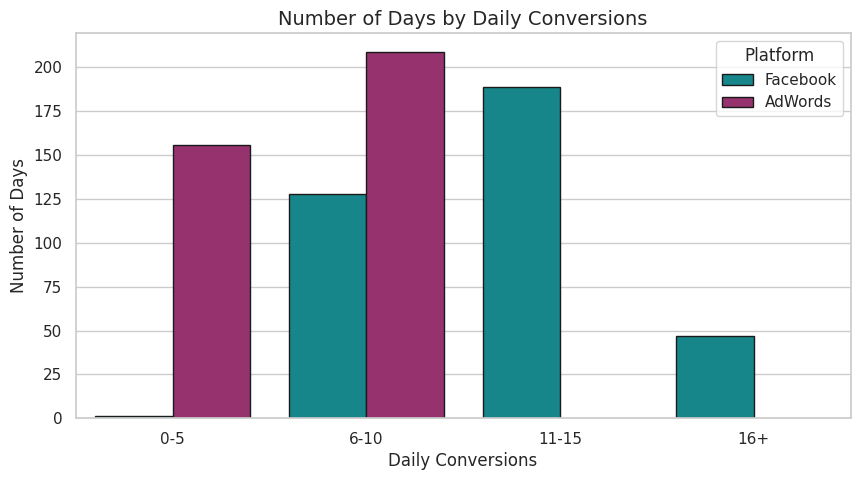

Platform,Facebook,AdWords
Conversion Group,,
0-5,1,156
6-10,128,209
11-15,189,0
16+,47,0


In [9]:
# Split daily conversions into 4 groups
ads['Conversion Group'] = pd.cut(ads['Conversions'], bins=[-1, 5, 10, 15, 100], labels=['0-5', '6-10', '11-15', '16+'])

plt.figure(figsize=(10, 5))
sns.countplot(data=ads, x='Conversion Group', hue='Platform', hue_order=platforms, palette=colors, edgecolor='k')
plt.title('Number of Days by Daily Conversions', fontsize=14)
plt.xlabel('Daily Conversions')
plt.ylabel('Number of Days')
plt.show()

pd.crosstab(ads['Conversion Group'], ads['Platform'])[platforms]

- **AdWords** had 5 or fewer conversions on 156 of its 365 days, and it never went above 10 conversions in a single day.
- **Facebook** had 11 or more conversions on 236 days (189 days in the 11-15 group and 47 days in the 16+ group).
- Facebook had only **1 day** with 5 or fewer conversions.

## 5. Do More Clicks Really Mean More Conversions?

In the scatter plots each dot is one day. If the dots rise towards the upper right, more clicks go together with more conversions.

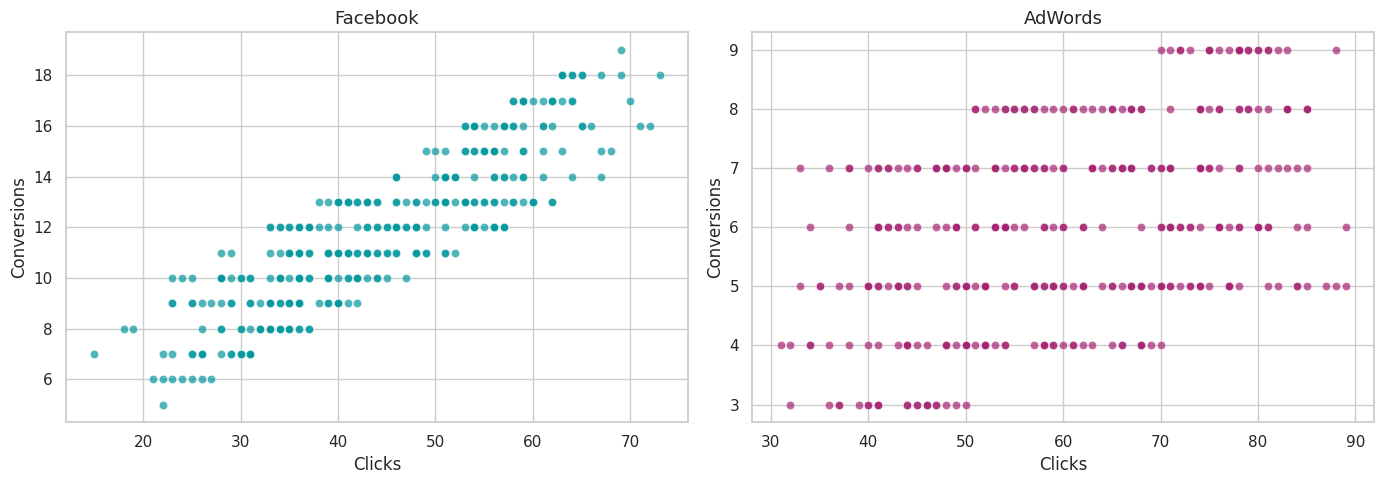

Correlation (Clicks vs Conversions)
Platform
Facebook    0.87
AdWords     0.45
dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, p in zip(axes, platforms):
    data = ads[ads['Platform'] == p]
    sns.scatterplot(data=data, x='Clicks', y='Conversions', color=colors[p], alpha=0.7, ax=ax)
    ax.set_title(p, fontsize=13)
plt.tight_layout()
plt.show()

# Correlation ranges from -1 to +1. A value close to +1 means a strong relationship
print('Correlation (Clicks vs Conversions)')
print(ads.groupby('Platform').apply(lambda d: d['Clicks'].corr(d['Conversions']), include_groups=False).round(2).loc[platforms])

- **Facebook (0.87):** strong relationship. When clicks go up, conversions go up almost in proportion.
- **AdWords (0.45):** moderate relationship. Even on days with many clicks, conversions are not guaranteed, which suggests many of the clicks are low quality.

### Does spending more money bring more conversions?

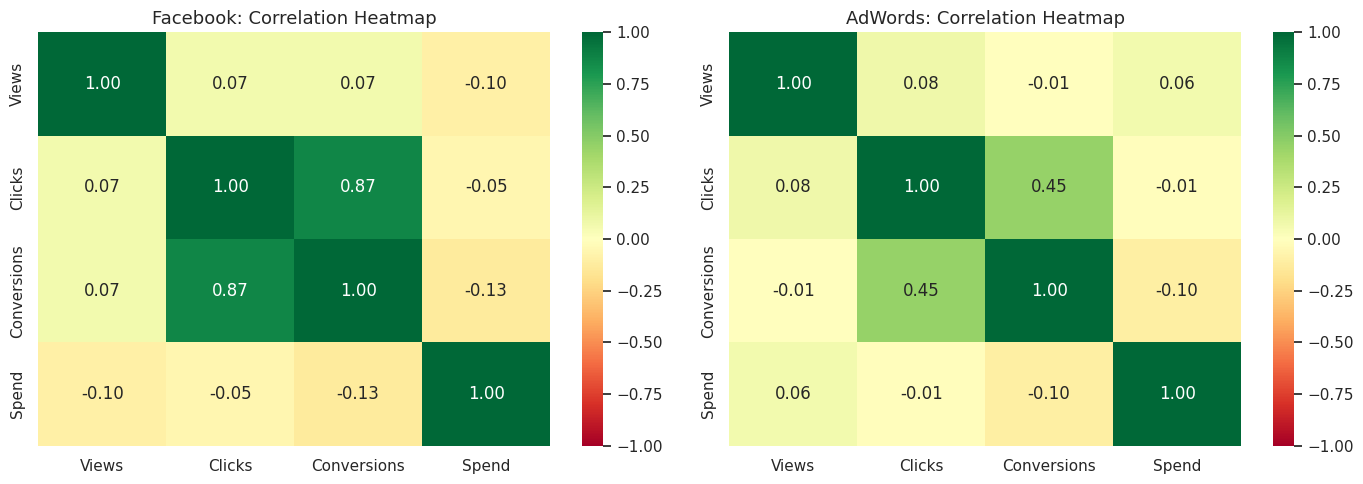

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, p in zip(axes, platforms):
    data = ads[ads['Platform'] == p][['Views', 'Clicks', 'Conversions', 'Spend']]
    sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='RdYlGn', vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'{p}: Correlation Heatmap', fontsize=13)
plt.tight_layout()
plt.show()

**Interesting finding:** On both platforms the correlation of **Spend** with Clicks and Conversions is close to **zero** (between -0.13 and -0.01).
In this data, days with higher spending did not bring more conversions.
This suggests that simply increasing the budget is not enough; **targeting and ad quality** matter more.

## 6. Time Analysis

### 6.1 Month-wise trend

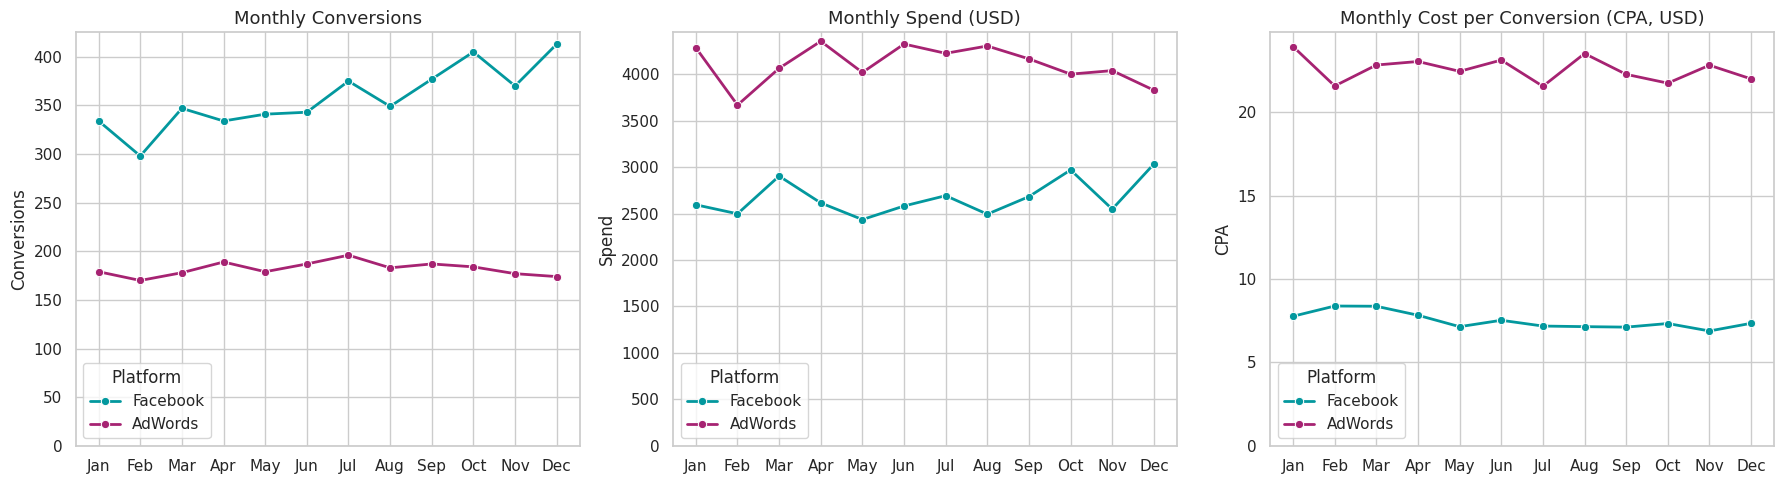

In [12]:
monthly = ads.groupby(['Month', 'Platform'])[['Views', 'Clicks', 'Conversions', 'Spend']].sum().reset_index()
monthly['CPA'] = monthly['Spend'] / monthly['Conversions']

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, title in zip(axes, ['Conversions', 'Spend', 'CPA'],
                             ['Monthly Conversions', 'Monthly Spend (USD)', 'Monthly Cost per Conversion (CPA, USD)']):
    sns.lineplot(data=monthly, x='Month', y=metric, hue='Platform', hue_order=platforms,
                 palette=colors, marker='o', linewidth=2, ax=ax)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('')
    ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

In [13]:
# Month-wise CPA table
cpa_table = monthly.pivot(index='Month', columns='Platform', values='CPA')[platforms].round(2)
cpa_table.index = month_names
cpa_table

Platform,Facebook,AdWords
Jan,7.77,23.93
Feb,8.38,21.57
Mar,8.37,22.83
Apr,7.83,23.04
May,7.14,22.45
Jun,7.52,23.12
Jul,7.18,21.55
Aug,7.14,23.51
Sep,7.11,22.27
Oct,7.33,21.74


- **Facebook conversions grew through the year:** from 334 in January to 413 in December (**about 24% growth**). Spend also increased (from $2,594 in January to $3,033 in December, about 17%), but conversions grew faster, so efficiency improved slightly.
- **AdWords stayed flat:** between 170 and 196 conversions every month with no growth. Its monthly spend was also higher than Facebook's in every month.
- **CPA:** Facebook's CPA ranged from $6.88 (Nov) to $8.38 (Feb), while AdWords ranged from $21.55 to $23.93. Even Facebook's worst month is far cheaper than AdWords' best month.

### 6.2 Cumulative growth: total conversions and total spend through the year

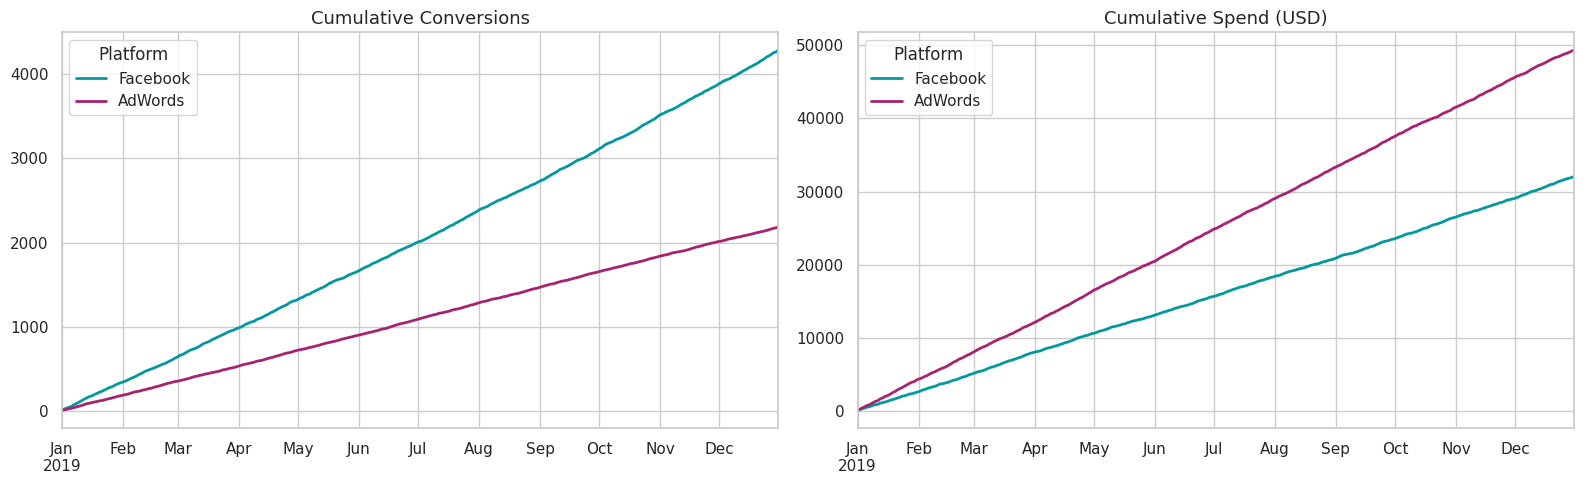

In [14]:
daily_conv = ads.pivot(index='Date', columns='Platform', values='Conversions')[platforms]
daily_spend = ads.pivot(index='Date', columns='Platform', values='Spend')[platforms]
line_colors = [colors[p] for p in platforms]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
daily_conv.cumsum().plot(ax=axes[0], color=line_colors, linewidth=2)
axes[0].set_title('Cumulative Conversions', fontsize=13)
daily_spend.cumsum().plot(ax=axes[1], color=line_colors, linewidth=2)
axes[1].set_title('Cumulative Spend (USD)', fontsize=13)
for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

The gap is clear in the cumulative charts: **the AdWords spend line is higher, but its conversions line is lower.**
AdWords took more of the budget and still produced about half the conversions of Facebook.

### 6.3 Daily trend (7-day moving average)

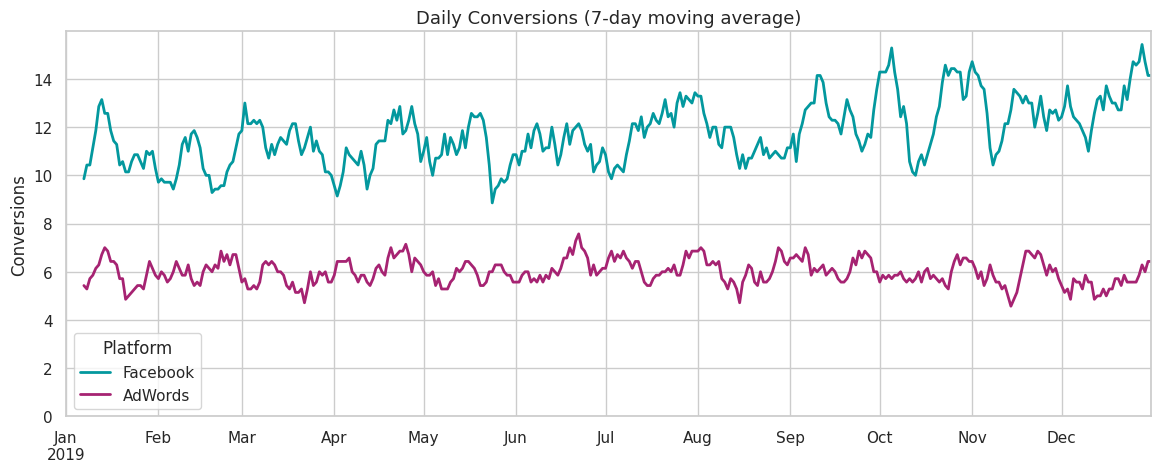

In [15]:
# Daily data is very jagged, so we use a 7-day average to see the trend clearly
fig, ax = plt.subplots(figsize=(14, 5))
daily_conv.rolling(7).mean().plot(ax=ax, color=line_colors, linewidth=2)
ax.set_title('Daily Conversions (7-day moving average)', fontsize=13)
ax.set_xlabel('')
ax.set_ylabel('Conversions')
ax.set_ylim(0, None)
plt.show()

The Facebook line stayed above the AdWords line for the whole year and slowly moved upward. The AdWords line stayed almost flat.

### 6.4 Weekday-wise performance

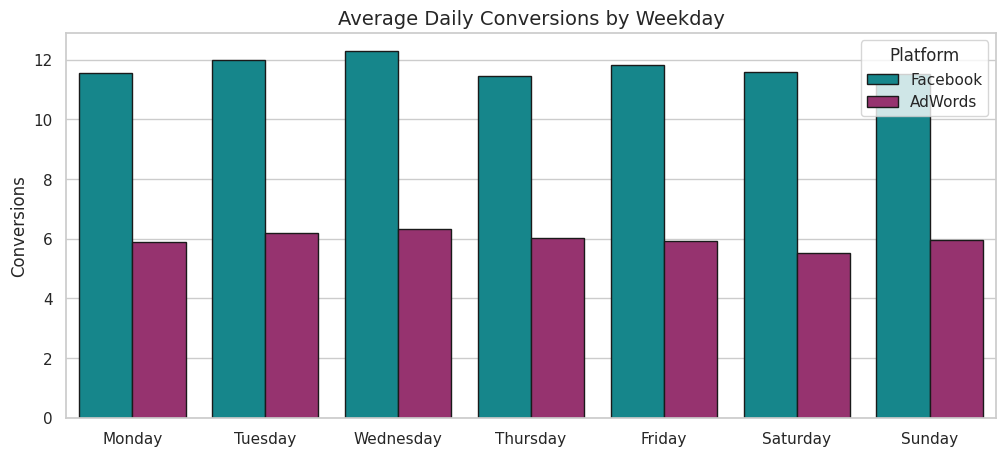

Conversions   Spend
Platform Day Type                     
Facebook Weekday         11.82   85.82
         Weekend         11.55   92.69
AdWords  Weekday          6.08  134.61
         Weekend          5.74  135.89

In [16]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(12, 5))
sns.barplot(data=ads, x='Weekday', y='Conversions', hue='Platform', order=weekday_order,
            hue_order=platforms, palette=colors, errorbar=None, edgecolor='k')
plt.title('Average Daily Conversions by Weekday', fontsize=14)
plt.xlabel('')
plt.show()

# Weekday vs Weekend
ads['Day Type'] = np.where(ads['Date'].dt.dayofweek >= 5, 'Weekend', 'Weekday')
ads.groupby(['Platform', 'Day Type'])[['Conversions', 'Spend']].mean().round(2).loc[platforms]

- The **day of the week has very little effect** on either platform. Facebook averages 11.5 to 12.3 conversions per day and AdWords averages 5.5 to 6.3.
- **Wednesday** is slightly the best day for both platforms, but the difference is too small to base budget decisions on.
- **Weekday vs weekend** also shows no big difference (Facebook: 11.82 vs 11.55, AdWords: 6.08 vs 5.74).
- So the budget should be planned **by platform, not by day of the week**.

## 7. Budget Efficiency and "What-If" Scenario

### How many conversions does every $100 buy?

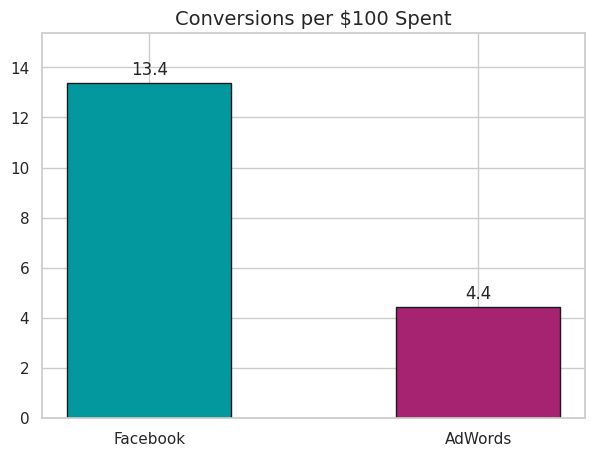

In [17]:
scorecard['Conversions per $100'] = scorecard['Conversions'] / scorecard['Spend'] * 100

plt.figure(figsize=(7, 5))
bars = plt.bar(scorecard.index, scorecard['Conversions per $100'],
               color=[colors[p] for p in scorecard.index], edgecolor='k', width=0.5)
plt.bar_label(bars, labels=[f'{v:.1f}' for v in scorecard['Conversions per $100']], padding=3, fontsize=12)
plt.title('Conversions per \\$100 Spent', fontsize=14)
plt.ylim(0, scorecard['Conversions per $100'].max() * 1.15)
plt.show()

### What if we move $10,000 of the AdWords budget to Facebook?

> **Note:** This is only simple arithmetic. It assumes that Facebook's CPA stays the same when the budget grows.
> In reality CPA can rise when spend increases, so any shift should first be tested on a small scale.

In [18]:
shift = 10000  # USD

conv_lost = shift / scorecard.loc['AdWords', 'CPA']
conv_gained = shift / scorecard.loc['Facebook', 'CPA']

print(f'Conversions from ${shift:,} on AdWords   : {conv_lost:,.0f}')
print(f'Conversions from ${shift:,} on Facebook  : {conv_gained:,.0f}')
print(f'Net extra conversions                    : {conv_gained - conv_lost:,.0f}')

Conversions from $10,000 on AdWords   : 443
Conversions from $10,000 on Facebook  : 1,338
Net extra conversions                    : 895


Under this simple estimate, moving $10,000 would give about **900 extra conversions** without increasing the total budget.

## 8. Final Insights and Recommendation

### Winner: Facebook Ads

| Metric | Facebook | AdWords | Better |
|---|---|---|---|
| Total Conversions | 4,286 | 2,183 | Facebook (about 2x) |
| Total Spend | $32,040 | $49,266 | Facebook (35% lower) |
| CTR | 2.02% | 1.28% | Facebook |
| Conversion Rate | 26.7% | 9.9% | Facebook (about 2.7x) |
| CPC | $1.99 | $2.24 | Facebook (slightly) |
| CPA (cost per conversion) | $7.48 | $22.57 | Facebook (about 3x cheaper) |
| Total Views / Clicks | 0.80M / 16,078 | 1.72M / 22,040 | AdWords |
| Trend over the year | Growing (+24%) | Flat | Facebook |

### Key takeaways
1. **Facebook wins on every metric that matters to the business** (conversions, CPA, conversion rate). AdWords is ahead only in reach (views and clicks).
2. **More clicks does not mean more sales.** AdWords got more clicks, but very few of them turned into customers.
3. **No direct relationship was found between spend and conversions.** Simply increasing the budget is not the solution.
4. **Facebook kept improving through the year**, while AdWords showed no growth.
5. **Day-of-week differences are tiny**, so choosing the right platform matters far more than choosing the right day.

### Recommendation
- Move part of the AdWords budget (for example 10-20%) to Facebook gradually and keep tracking the results.
- Do not shut down AdWords completely. Check which keywords and audiences actually convert and cut the rest.
- If AdWords is kept, work on improving its **conversion rate** (landing page, keywords, targeting).

### Limitations
- The data covers only **one year**, so we cannot say much about seasonality (festivals, sale seasons).
- We have no **revenue** data, so true ROI cannot be calculated. CPA (cost per conversion) is used as a proxy.
- This is observational data and not a controlled experiment, so we cannot say exactly why Facebook performs better.

### Next steps
- Calculate **ROI / ROAS** once revenue per conversion is available
- Deep dive into individual campaigns (the monthly campaign names in the data)
- Build a Power BI / Tableau dashboard